# 📊 Fraud Detection Analysis - Detailed

## Healthcare Claims Fraud Statistical Analysis

This notebook provides comprehensive statistical analysis of fraudulent vs legitimate healthcare claims.

**Analysis includes:**
- Dataset overview and structure
- Fraud distribution analysis
- Financial comparison by fraud status
- Claim type breakdown
- Correlation analysis with fraud
- Statistical significance testing (T-tests)
- Interactive visualizations
- Detailed statistical reports
- Export of fraudulent claims for review

## Step 0: Import Libraries

In [1]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-darkgrid')
colors = {'legitimate': '#1D9E75', 'fraudulent': '#E85D24'}

print('✓ All libraries imported successfully!')

✓ All libraries imported successfully!


## Step 1: Load Dataset

In [4]:
# Load the fraud-labeled data
df = pd.read_csv('d:/SecureHIC/src/outputs/cms_fhir_with_fraud_target_from_code.csv')

print(f'✓ Dataset loaded successfully!')
print(f'  Shape: {df.shape}')
print(f'  Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')
print(f'\nFirst few rows:')
df.head()

✓ Dataset loaded successfully!
  Shape: (4000, 29)
  Memory: 2.44 MB

First few rows:


,secure_patient_id,claim_type,insurance_status,coverage_start,coverage_end,payment_amount,total_charged,total_line_items,num_diagnosis_codes,num_procedure_codes,...,line_benefit_total,line_paid_to_provider_total,line_paid_to_patient_total,line_deductible_total,line_coinsurance_total,line_priorpayer_total,line_all_adjudication_total,service_duration_days,outcome,is_fraud
0,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,2003-04-29,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
1,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,2003-04-29,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
2,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
3,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,16.95,1,0,1,...,13.56,0.0,0.0,0.0,5938.75,0.0,5972.65,0,complete,0
4,sha3_512:3e837d307a9f240cc7cbd1bb6186afa11b39a...,PDE,active,NaN,NaN,NaN,44.17,1,0,1,...,35.34,0.0,0.0,0.0,222.55,0.0,310.89,0,complete,0


## Step 2: Dataset Overview

In [6]:
print("="*80)
print("DATASET OVERVIEW")
print("="*80)

print(f'\nTotal records: {len(df):,}')
print(f'Total columns: {len(df.columns)}')
print(f'Shape: {df.shape}')

print('\nColumn Details:')
print('{:<35} {:<12} {:<10} {:<10}'.format('Column', 'Type', 'Missing', 'Unique'))
print("-" * 70)

for col in df.columns:
    dtype = str(df[col].dtype)
    missing = df[col].isnull().sum()
    unique = df[col].nunique()
    print(f'{col:<35} {dtype:<12} {missing:<10} {unique:<10}')

DATASET OVERVIEW

Total records: 4,000
Total columns: 29
Shape: (4000, 29)

Column Details:
Column                              Type         Missing    Unique    
----------------------------------------------------------------------
secure_patient_id                   object       0          4         
claim_type                          object       0          7         
insurance_status                    object       0          1         
coverage_start                      object       1683       5         
coverage_end                        object       3683       2         
payment_amount                      float64      2508       246       
total_charged                       float64      0          480       
total_line_items                    int64        0          22        
num_diagnosis_codes                 int64        0          18        
num_procedure_codes                 int64        0          17        
service_category_count              int64        0      

## Step 3: Fraud Target Distribution

FRAUD TARGET DISTRIBUTION

Fraud distribution:
  Legitimate (0):  3,950 ( 98.75%) ✓
  Fraudulent (1):     50 (  1.25%) ⚠️


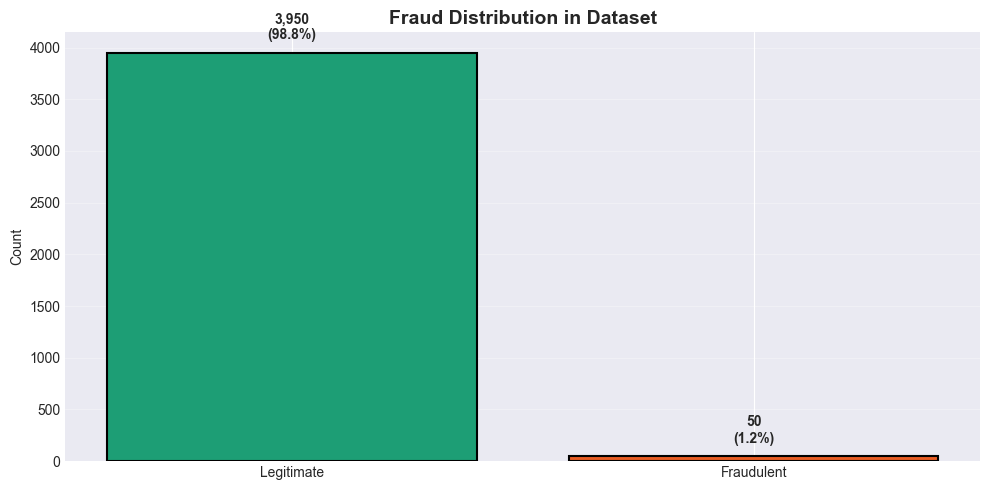

In [7]:
print("="*80)
print("FRAUD TARGET DISTRIBUTION")
print("="*80)

fraud_counts = df['is_fraud'].value_counts().sort_index()
legit_count = fraud_counts.get(0, 0)
fraud_count = fraud_counts.get(1, 0)

print(f'\nFraud distribution:')
print(f'  Legitimate (0): {legit_count:>6,} ({legit_count/len(df)*100:>6.2f}%) ✓')
print(f'  Fraudulent (1): {fraud_count:>6,} ({fraud_count/len(df)*100:>6.2f}%) ⚠️')

# Visualization
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(['Legitimate', 'Fraudulent'], 
              [legit_count, fraud_count], 
              color=[colors['legitimate'], colors['fraudulent']],
              edgecolor='black',
              linewidth=1.5)

ax.set_title('Fraud Distribution in Dataset', fontsize=14, fontweight='bold')
ax.set_ylabel('Count')
ax.grid(axis='y', alpha=0.3)

# Add value labels
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + 100,
           f'{int(height):,}\n({height/len(df)*100:.1f}%)',
           ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## Step 4: Financial Comparison - Fraudulent vs Legitimate

In [8]:
print("="*80)
print("FINANCIAL COMPARISON: FRAUDULENT vs LEGITIMATE")
print("="*80)

legitimate = df[df['is_fraud'] == 0]
fraudulent = df[df['is_fraud'] == 1]

financial_cols = [
    'payment_amount', 'total_charged', 'line_deductible_total',
    'line_coinsurance_total', 'line_submitted_total', 'line_benefit_total'
]

for col in financial_cols:
    if col in df.columns:
        legit_mean = legitimate[col].mean()
        fraud_mean = fraudulent[col].mean()
        legit_median = legitimate[col].median()
        fraud_median = fraudulent[col].median()
        diff_pct = (fraud_mean - legit_mean) / legit_mean * 100 if legit_mean != 0 else 0
        
        print(f'\n{col}:')
        print(f'  Legitimate - Mean: ${legit_mean:>12,.2f} | Median: ${legit_median:>12,.2f}')
        print(f'  Fraudulent - Mean: ${fraud_mean:>12,.2f} | Median: ${fraud_median:>12,.2f}')
        print(f'  Difference: ${fraud_mean - legit_mean:>12,.2f} ({diff_pct:+.1f}%)')

FINANCIAL COMPARISON: FRAUDULENT vs LEGITIMATE

payment_amount:
  Legitimate - Mean: $    2,212.62 | Median: $    1,028.87
  Fraudulent - Mean: $    2,712.14 | Median: $    1,233.77
  Difference: $      499.52 (+22.6%)

total_charged:
  Legitimate - Mean: $      896.64 | Median: $      260.78
  Fraudulent - Mean: $      885.09 | Median: $        2.58
  Difference: $      -11.55 (-1.3%)

line_deductible_total:
  Legitimate - Mean: $        4.38 | Median: $        0.00
  Fraudulent - Mean: $        0.00 | Median: $        0.00
  Difference: $       -4.38 (-100.0%)

line_coinsurance_total:
  Legitimate - Mean: $    1,324.80 | Median: $      405.95
  Fraudulent - Mean: $      962.86 | Median: $      444.92
  Difference: $     -361.94 (-27.3%)

line_submitted_total:
  Legitimate - Mean: $    1,462.00 | Median: $        0.00
  Fraudulent - Mean: $    2,257.49 | Median: $        0.00
  Difference: $      795.49 (+54.4%)

line_benefit_total:
  Legitimate - Mean: $      239.28 | Median: $      

## Step 5: Fraud by Claim Type

FRAUD BY CLAIM TYPE

            fraudulent_count  total_count  fraud_rate
claim_type                                           
71                        11          448    0.024554
PDE                       31         2508    0.012360
40                         8          808    0.009901
10                         0            4    0.000000
20                         0           20    0.000000
60                         0           68    0.000000
82                         0          144    0.000000


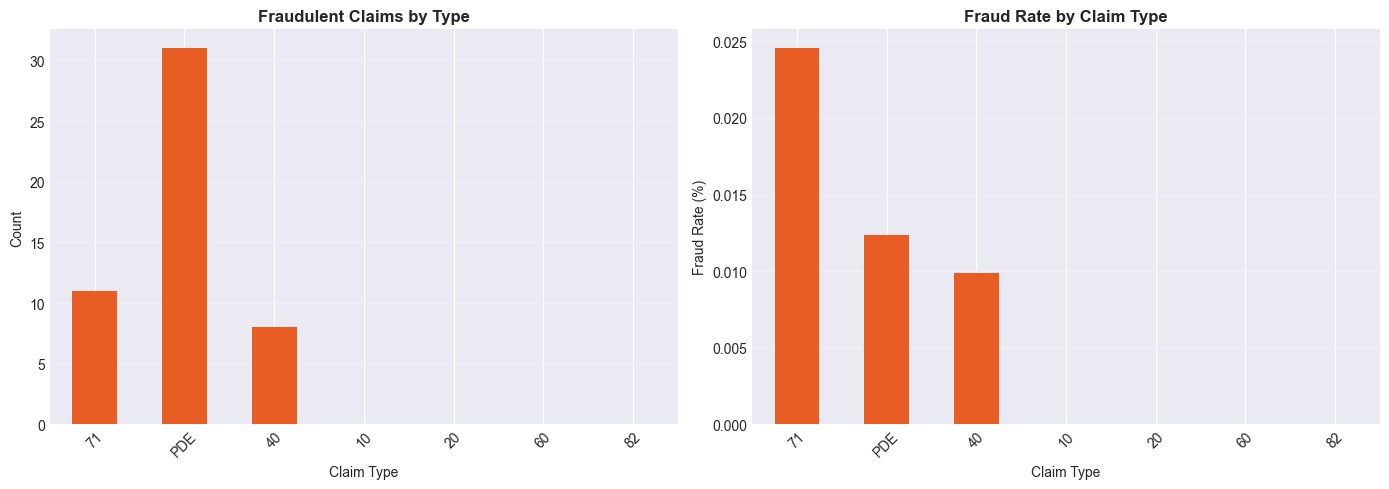

In [9]:
print("="*80)
print("FRAUD BY CLAIM TYPE")
print("="*80)

claim_fraud = df.groupby('claim_type')['is_fraud'].agg(['sum', 'count', 'mean'])
claim_fraud.columns = ['fraudulent_count', 'total_count', 'fraud_rate']
claim_fraud = claim_fraud.sort_values('fraud_rate', ascending=False)

print(f'\n{claim_fraud.to_string()}')

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Count of fraudulent by type
claim_fraud['fraudulent_count'].plot(kind='bar', ax=ax1, color=colors['fraudulent'])
ax1.set_title('Fraudulent Claims by Type', fontsize=12, fontweight='bold')
ax1.set_xlabel('Claim Type')
ax1.set_ylabel('Count')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Fraud rate by type
claim_fraud['fraud_rate'].plot(kind='bar', ax=ax2, color=colors['fraudulent'])
ax2.set_title('Fraud Rate by Claim Type', fontsize=12, fontweight='bold')
ax2.set_xlabel('Claim Type')
ax2.set_ylabel('Fraud Rate (%)')
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45)
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Step 6: Correlation Analysis with Fraud

CORRELATION WITH FRAUD

Calculating correlations for 20 numeric features...

Top 10 features correlated with fraud:
Feature                                   Correlation
-------------------------------------------------------
total_line_items                               0.0565
line_eligible_total                            0.0439
line_benefit_total                             0.0355
service_category_count                         0.0228
avg_payment_per_line                           0.0209
num_procedure_codes                            0.0198
line_submitted_total                           0.0155
avg_charge_per_line                            0.0104
line_priorpayer_total                         -0.0100
payment_amount                                 0.0095


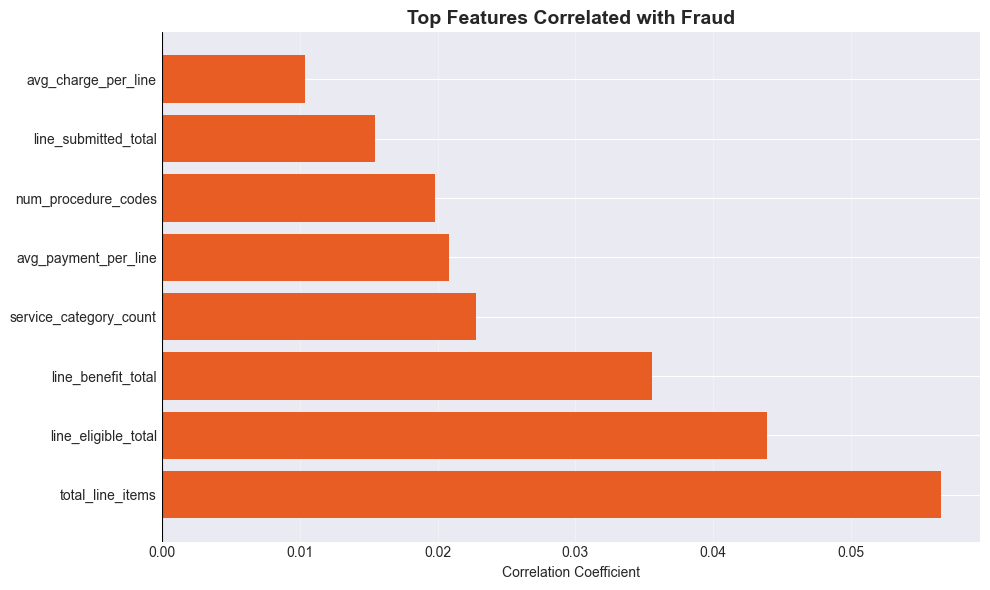

In [10]:
print("="*80)
print("CORRELATION WITH FRAUD")
print("="*80)

numeric_cols = df.select_dtypes(include=['number']).columns
print(f'\nCalculating correlations for {len(numeric_cols) - 1} numeric features...')

correlations = {}
for col in numeric_cols:
    if col != 'is_fraud':
        corr = df[col].corr(df['is_fraud'])
        if not np.isnan(corr):
            correlations[col] = corr

# Sort by absolute correlation
sorted_corr = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)

print(f'\nTop 10 features correlated with fraud:')
print(f'{"Feature":<40} {"Correlation":>12}')
print("-" * 55)

for col, corr in sorted_corr[:10]:
    print(f'{col:<40} {corr:>12.4f}')

# Visualization
fig, ax = plt.subplots(figsize=(10, 6))
top_corr = dict(sorted_corr[:8])
colors_bar = [colors['fraudulent'] if v > 0 else '#3B8BD4' for v in top_corr.values()]
ax.barh(list(top_corr.keys()), list(top_corr.values()), color=colors_bar)
ax.set_title('Top Features Correlated with Fraud', fontsize=14, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')
ax.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7: Statistical Significance Testing (T-Tests)

In [11]:
print("="*80)
print("STATISTICAL COMPARISON (T-TESTS)")
print("="*80)

print(f'\nComparing fraudulent vs legitimate claims using independent t-tests:')
print(f'H0: Fraudulent and legitimate claims have equal means')
print(f'Significance level: α = 0.05\n')

test_cols = ['payment_amount', 'total_charged', 'line_deductible_total']

for col in test_cols:
    if col in df.columns:
        legit_vals = legitimate[col].dropna()
        fraud_vals = fraudulent[col].dropna()
        
        t_stat, p_value = stats.ttest_ind(fraud_vals, legit_vals)
        
        print(f'\n{col}:')
        print(f'  Legitimate Mean: ${legit_vals.mean():>12,.2f}')
        print(f'  Fraudulent Mean: ${fraud_vals.mean():>12,.2f}')
        print(f'  T-statistic: {t_stat:>12.4f}')
        print(f'  P-value: {p_value:>12.6f}')
        
        if p_value < 0.05:
            print(f'  Result: SIGNIFICANT DIFFERENCE (reject H0) ✓')
        else:
            print(f'  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)')

STATISTICAL COMPARISON (T-TESTS)

Comparing fraudulent vs legitimate claims using independent t-tests:
H0: Fraudulent and legitimate claims have equal means
Significance level: α = 0.05


payment_amount:
  Legitimate Mean: $    2,212.62
  Fraudulent Mean: $    2,712.14
  T-statistic:       0.3671
  P-value:     0.713603
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)

total_charged:
  Legitimate Mean: $      896.64
  Fraudulent Mean: $      885.09
  T-statistic:      -0.0210
  P-value:     0.983257
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)

line_deductible_total:
  Legitimate Mean: $        4.38
  Fraudulent Mean: $        0.00
  T-statistic:      -0.5440
  P-value:     0.586500
  Result: NO SIGNIFICANT DIFFERENCE (fail to reject H0)


## Step 8: Fraud Indicators Explanation

In [12]:
fraud_indicators_info = """
════════════════════════════════════════════════════════════════════════════════
FRAUD INDICATORS USED IN DETECTION
════════════════════════════════════════════════════════════════════════════════

The fraud detection algorithm uses 5 indicators:

1️⃣ HIGH DEDUCTIBLE RATIO (>30% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Deductible > 30% of submitted amount
   Normal Range: 10-20%
   Example: Submitted $100, Deductible $40 → FRAUD INDICATOR!
   Risk: Billing error or intentional fraud

2️⃣ HIGH COINSURANCE RATIO (>50% of benefit)
   ─────────────────────────────────────────────────────────────────────────
   What: Patient coinsurance > 50% of benefit amount
   Normal Range: 10-30%
   Example: Benefit $200, Coinsurance $150 → FRAUD INDICATOR!
   Risk: Claim miscoding or patient abuse

3️⃣ HIGH ADJUSTMENTS (>50% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Adjustments > 50% of submitted amount
   Normal Range: <20%
   Example: Submitted $100, Adjustments $60 → FRAUD INDICATOR!
   Risk: Excessive corrections or claim reversal patterns

4️⃣ MANY ADJUDICATIONS (>10 line items adjusted)
   ─────────────────────────────────────────────────────────────────────────
   What: More than 10 line items need adjustments on single claim
   Normal Range: 0-5 items
   Example: 15 items adjusted out of 20 → FRAUD INDICATOR!
   Risk: Suspicious claim processing patterns

5️⃣ EXTREME BENEFIT AMOUNTS (>95th percentile)
   ─────────────────────────────────────────────────────────────────────────
   What: Benefit amount exceeds 95th percentile
   Normal Range: <$7,000 (median: $200)
   Example: Benefit $10,000 while median $200 → FRAUD INDICATOR!
   Risk: Inflated or fraudulent claim amounts

════════════════════════════════════════════════════════════════════════════════
CLASSIFICATION RULE
════════════════════════════════════════════════════════════════════════════════

Fraud Score = Count of triggered indicators (0-5)

THRESHOLD: Score >= 2 → FRAUDULENT
           Score < 2  → LEGITIMATE

Examples:
  Score 0: Clean claim → ✓ Legitimate
  Score 1: One issue, may be acceptable → ✓ Legitimate
  Score 2: Multiple concerns → ⚠️ FRAUDULENT
  Score 3+: Highly suspicious → ⚠️ FRAUDULENT
════════════════════════════════════════════════════════════════════════════════
"""

print(fraud_indicators_info)


════════════════════════════════════════════════════════════════════════════════
FRAUD INDICATORS USED IN DETECTION
════════════════════════════════════════════════════════════════════════════════

The fraud detection algorithm uses 5 indicators:

1️⃣ HIGH DEDUCTIBLE RATIO (>30% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Deductible > 30% of submitted amount
   Normal Range: 10-20%
   Example: Submitted $100, Deductible $40 → FRAUD INDICATOR!
   Risk: Billing error or intentional fraud

2️⃣ HIGH COINSURANCE RATIO (>50% of benefit)
   ─────────────────────────────────────────────────────────────────────────
   What: Patient coinsurance > 50% of benefit amount
   Normal Range: 10-30%
   Example: Benefit $200, Coinsurance $150 → FRAUD INDICATOR!
   Risk: Claim miscoding or patient abuse

3️⃣ HIGH ADJUSTMENTS (>50% of submitted)
   ─────────────────────────────────────────────────────────────────────────
   What: Adjustments > 50% of

## Step 9: Fraudulent Claims Breakdown

In [13]:
print("="*80)
print("FRAUDULENT CLAIMS BREAKDOWN")
print("="*80)

if len(fraudulent) > 0:
    print(f'\nTotal fraudulent claims: {len(fraudulent)}')
    print(f'\nSample of fraudulent claims (first 10):')
    
    sample_cols = ['claim_type', 'total_charged', 'payment_amount', 
                   'line_deductible_total', 'line_coinsurance_total', 'is_fraud']
    sample_cols = [col for col in sample_cols if col in df.columns]
    
    print(fraudulent[sample_cols].head(10).to_string())
    
    print(f'\nFraudulent claims by claim type:')
    if 'claim_type' in fraudulent.columns:
        print(fraudulent['claim_type'].value_counts())
else:
    print('No fraudulent claims in dataset')

FRAUDULENT CLAIMS BREAKDOWN

Total fraudulent claims: 50

Sample of fraudulent claims (first 10):
    claim_type  total_charged  payment_amount  line_deductible_total  line_coinsurance_total  is_fraud
7          PDE          44.17             NaN                    0.0                  222.55         1
15         PDE          29.81             NaN                    0.0                    0.00         1
18         PDE         260.78             NaN                    0.0                  233.00         1
20          71           0.00         1130.01                    0.0                 1130.01         1
22          71           0.00         1130.01                    0.0                 1130.01         1
24         PDE         432.96             NaN                    0.0                  633.48         1
25         PDE         432.96             NaN                    0.0                  633.48         1
26         PDE         432.96             NaN                    0.0          

## Step 10: Comprehensive Visualization Dashboard

✓ Saved: fraud_analysis_visualization.png


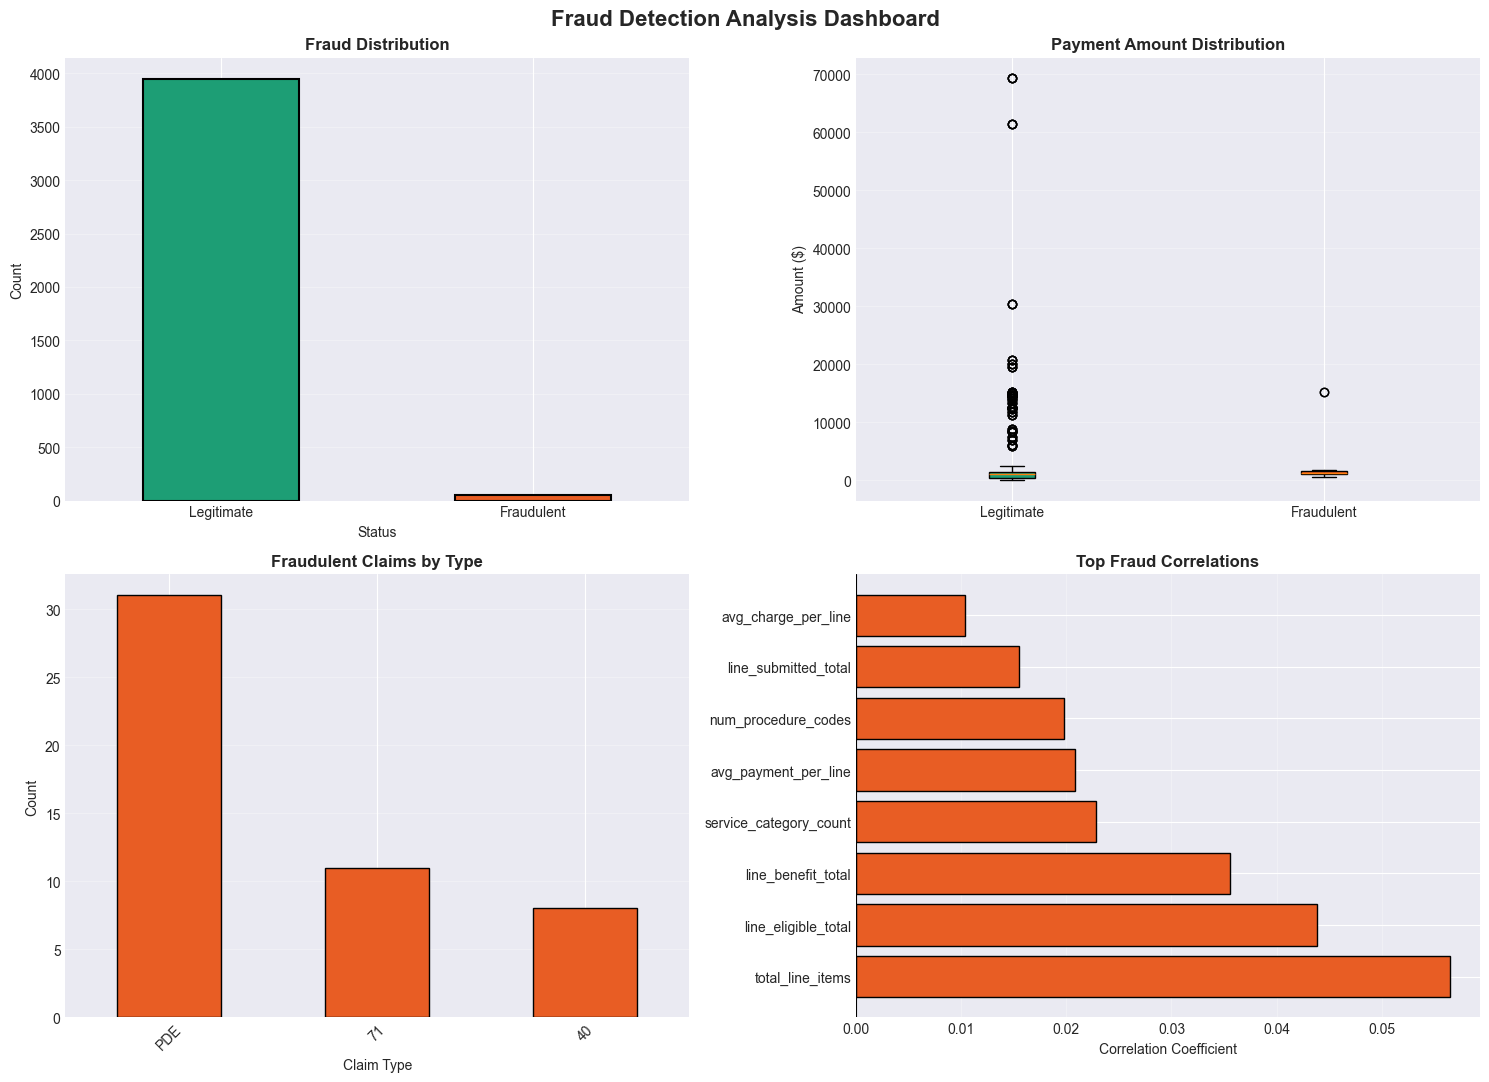

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Fraud Detection Analysis Dashboard', fontsize=16, fontweight='bold')

# Plot 1: Fraud distribution
ax1 = axes[0, 0]
fraud_counts.plot(kind='bar', ax=ax1, color=[colors['legitimate'], colors['fraudulent']],
                  edgecolor='black', linewidth=1.5)
ax1.set_title('Fraud Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Status')
ax1.set_ylabel('Count')
ax1.set_xticklabels(['Legitimate', 'Fraudulent'], rotation=0)
ax1.grid(axis='y', alpha=0.3)

# Plot 2: Payment amount distribution
ax2 = axes[0, 1]
data_to_plot = [legitimate['payment_amount'].dropna(), fraudulent['payment_amount'].dropna()]
bp = ax2.boxplot(data_to_plot, labels=['Legitimate', 'Fraudulent'], patch_artist=True)
for patch, color in zip(bp['boxes'], [colors['legitimate'], colors['fraudulent']]):
    patch.set_facecolor(color)
ax2.set_title('Payment Amount Distribution', fontsize=12, fontweight='bold')
ax2.set_ylabel('Amount ($)')
ax2.grid(axis='y', alpha=0.3)

# Plot 3: Fraudulent claims by type
ax3 = axes[1, 0]
claim_type_fraud = df[df['is_fraud'] == 1]['claim_type'].value_counts()
if len(claim_type_fraud) > 0:
    claim_type_fraud.plot(kind='bar', ax=ax3, color=colors['fraudulent'], edgecolor='black')
    ax3.set_title('Fraudulent Claims by Type', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Claim Type')
    ax3.set_ylabel('Count')
    ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45)
    ax3.grid(axis='y', alpha=0.3)

# Plot 4: Feature correlation
ax4 = axes[1, 1]
top_corr = dict(sorted_corr[:8])
colors_bar = [colors['fraudulent'] if v > 0 else '#3B8BD4' for v in top_corr.values()]
ax4.barh(list(top_corr.keys()), list(top_corr.values()), color=colors_bar, edgecolor='black')
ax4.set_title('Top Fraud Correlations', fontsize=12, fontweight='bold')
ax4.set_xlabel('Correlation Coefficient')
ax4.axvline(0, color='black', linestyle='-', linewidth=0.8)
ax4.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('fraud_analysis_visualization.png', dpi=150, bbox_inches='tight')
print('✓ Saved: fraud_analysis_visualization.png')
plt.show()

## Step 11: Export Detailed Data Files

In [17]:
# Export fraudulent claims details
fraudulent_export = fraudulent[[col for col in 
    ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 
     'line_deductible_total', 'line_coinsurance_total', 'is_fraud'] 
    if col in df.columns]].copy()

fraudulent_export.to_csv('fraudulent_claims_details.csv', index=False)
print(f'✓ Saved fraudulent claims: fraudulent_claims_details.csv')
print(f'  Records: {len(fraudulent_export)}')
print(f'  Columns: {list(fraudulent_export.columns)}')

# Export legitimate claims sample
legitimate_sample = legitimate.sample(min(100, len(legitimate)))[[
    col for col in ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'is_fraud'] 
    if col in df.columns
]].copy()

legitimate_sample.to_csv('legitimate_claims_sample.csv', index=False)
print(f'\n✓ Saved legitimate sample: legitimate_claims_sample.csv')
print(f'  Records: {len(legitimate_sample)}')
print(f'  Columns: {list(legitimate_sample.columns)}')

print(f'\n✅ DETAILED ANALYSIS COMPLETE!')
print(f'\nGenerated files:')
print(f'  1. fraud_analysis_visualization.png - Charts and dashboards')
print(f'  2. fraud_analysis_report.txt - Statistical report')
print(f'  3. fraudulent_claims_details.csv - Fraudulent claims for review')
print(f'  4. legitimate_claims_sample.csv - Sample of legitimate claims')

✓ Saved fraudulent claims: fraudulent_claims_details.csv
  Records: 50
  Columns: ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'line_deductible_total', 'line_coinsurance_total', 'is_fraud']

✓ Saved legitimate sample: legitimate_claims_sample.csv
  Records: 100
  Columns: ['secure_patient_id', 'claim_type', 'total_charged', 'payment_amount', 'is_fraud']

✅ DETAILED ANALYSIS COMPLETE!

Generated files:
  1. fraud_analysis_visualization.png - Charts and dashboards
  2. fraud_analysis_report.txt - Statistical report
  3. fraudulent_claims_details.csv - Fraudulent claims for review
  4. legitimate_claims_sample.csv - Sample of legitimate claims
